# Task 1–2 – Chuỗi PM2.5 và khí tượng Hà Nội: khám phá dữ liệu (EDA)

Notebook này mô tả bộ dữ liệu chuỗi thời gian dùng chung cho Task 1 (dự báo PM2.5 sau 2 giờ) và Task 2 (dự báo 5 giờ liên tiếp). Mô hình Task 1 nằm ở notebook `02_task1_model.ipynb`.

**Nguồn dữ liệu.** Số liệu theo giờ tải từ Open-Meteo cho Hà Nội, từ 01/01/2023 đến 31/12/2025 (giờ GMT+7):
- khí tượng: Historical Weather API (tái phân tích ERA5), điểm lưới 21,00°N 105,75°E;
- chất lượng không khí: Air Quality API (mô hình CAMS của Copernicus), điểm lưới 21,00°N 105,90°E.

PM2.5 ở đây là số của mô hình khí quyển CAMS cho một ô lưới, không phải số đo tại trạm. Nhờ vậy chuỗi liền mạch, không đứt quãng như số liệu trạm.

**File dùng:** `FinalDeepData/task1_2/hanoi_hourly_2023_2025_v1.csv`, đọc bằng hàm `load_hourly` trong `FinalDeepData/common/data_utils.py`. Biến cần dự báo (`pred_column`) là `pm2_5`, đơn vị µg/m³. Trên Colab, tải `FinalDeepData_hoan_chinh.zip` lên rồi bỏ dấu `#` ở dòng `!unzip` bên dưới.

In [1]:
# !unzip -q FinalDeepData_hoan_chinh.zip      # chỉ cần trên Colab

import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = "FinalDeepData"
sys.path.append(os.path.join(DATA_ROOT, "common"))
from data_utils import load_hourly, make_windows
import metrics

FIG_DIR = os.path.join("task1_outputs", "figures")
RESULT_DIR = os.path.join("task1_outputs", "results")
for d in (FIG_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

# Kiểu hình: lưới mờ, bỏ viền trên/phải; màu theo thứ tự cố định
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eda100", "test": "#eb6834"}

df = load_hourly(os.path.join(DATA_ROOT, "task1_2", "hanoi_hourly_2023_2025_v1.csv"))
with open(os.path.join(DATA_ROOT, "task1_2", "columns_units_v1.json"), encoding="utf-8") as f:
    UNITS = json.load(f)
VARIABLES = [c for c in df.columns if c != "split"]
print(f"{len(df)} giờ, từ {df.index.min()} đến {df.index.max()}")
df.head()

26304 giờ, từ 2023-01-01 00:00:00 đến 2025-12-31 23:00:00


,temperature_2m,relative_humidity_2m,surface_pressure,wind_speed_10m,wind_speed_100m,precipitation,pm10,pm2_5,nitrogen_dioxide,split
time,,,,,,,,,,
2023-01-01 00:00:00,13.4,81,1022.7,6.2,13.0,0.0,74.7,52.4,8.8,train
2023-01-01 01:00:00,13.0,85,1022.4,5.4,12.5,0.0,64.3,45.1,6.5,train
2023-01-01 02:00:00,13.2,85,1021.9,5.8,12.8,0.0,57.6,40.4,5.7,train
2023-01-01 03:00:00,12.0,92,1021.7,5.5,13.4,0.0,54.7,38.3,5.8,train
2023-01-01 04:00:00,12.0,91,1021.9,6.0,13.2,0.0,54.0,37.8,6.4,train


## 1. Tổng quan và chất lượng dữ liệu

Hàm `load_hourly` báo lỗi nếu chuỗi không liền mạch theo từng giờ. Ô dưới kiểm tra thêm ô trống, dòng trùng và giá trị âm.

In [2]:
print("Ô trống:", int(df.isna().sum().sum()), "| giờ trùng:", int(df.index.duplicated().sum()),
      "| giá trị âm:", int((df[VARIABLES] < 0).sum().sum()))
desc = df[VARIABLES].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.insert(0, "đơn vị", [UNITS[c] for c in desc.index])
desc.round(2)

Ô trống: 0 | giờ trùng: 0 | giá trị âm: 0


,đơn vị,mean,std,min,25%,50%,75%,max
temperature_2m,°C,24.96,5.57,8.2,20.9,25.9,28.9,39.8
relative_humidity_2m,%,79.44,13.62,23.0,71.0,82.0,91.0,100.0
surface_pressure,hPa,1008.96,7.59,984.3,1002.8,1008.4,1014.9,1032.3
wind_speed_10m,km/h,7.42,3.85,0.0,4.6,6.8,9.7,48.1
wind_speed_100m,km/h,12.70,6.67,0.0,7.6,12.1,17.1,76.4
precipitation,mm,0.22,0.82,0.0,0.0,0.0,0.1,22.4
pm10,μg/m³,57.20,33.44,4.3,33.5,48.9,72.2,291.5
pm2_5,μg/m³,45.04,27.49,3.0,25.6,38.1,56.7,232.8
nitrogen_dioxide,μg/m³,26.25,19.53,0.0,12.2,21.1,34.3,161.0


**Nhận xét.** Chuỗi đủ 26.304 giờ (3 năm), không có ô trống, giờ trùng hay giá trị âm, nên không cần điền khuyết. PM2.5 trung bình 45 µg/m³, gấp 3 lần ngưỡng khuyến nghị trung bình 24 giờ của WHO (15 µg/m³) và gấp 9 lần ngưỡng trung bình năm (5 µg/m³); có những giờ lên tới 233 µg/m³. Lượng mưa phần lớn bằng 0, chỉ một số ít giờ có mưa lớn.

## 2. Chia tập theo thời gian

Dữ liệu chuỗi thời gian phải chia theo thời gian, không xáo trộn, để mô hình không "nhìn thấy tương lai". Cột `split` có sẵn trong file:
- **train:** 2023–2024;
- **validation:** 01–06/2025;
- **test:** 07–12/2025 (có mùa đông cuối năm).

In [3]:
split_table = (df.groupby("split", sort=False)
                 .agg(bat_dau=("pm2_5", lambda s: s.index.min()), ket_thuc=("pm2_5", lambda s: s.index.max()),
                      so_gio=("pm2_5", "size"), pm25_trung_binh=("pm2_5", "mean"), pm25_trung_vi=("pm2_5", "median"),
                      pm25_lon_nhat=("pm2_5", "max")))
split_table.round(1)

,bat_dau,ket_thuc,so_gio,pm25_trung_binh,pm25_trung_vi,pm25_lon_nhat
split,,,,,,
train,2023-01-01,2024-12-31 23:00:00,17544,41.5,35.6,203.0
validation,2025-01-01,2025-06-30 23:00:00,4344,53.9,45.5,232.8
test,2025-07-01,2025-12-31 23:00:00,4416,50.2,41.8,189.1


## 3. PM2.5 theo thời gian

Hình dưới vẽ trung bình theo ngày và trung bình trượt 30 ngày của PM2.5; nền màu đánh dấu ba tập.

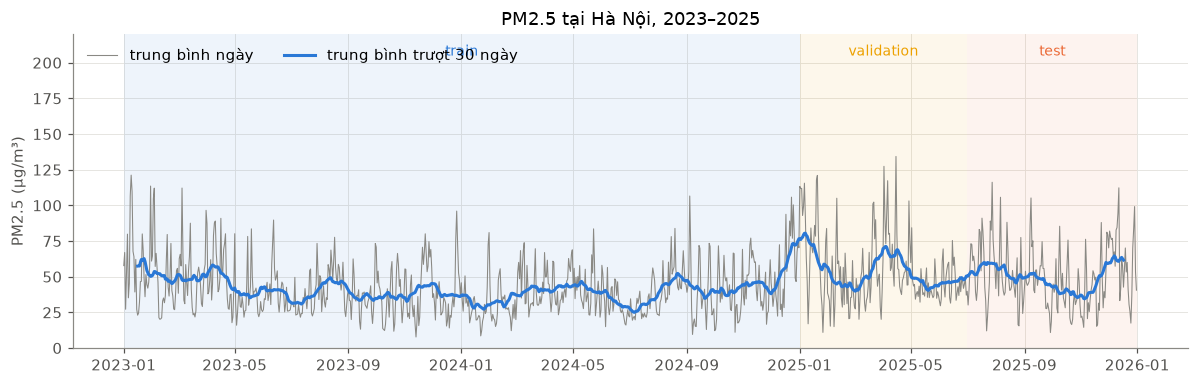

In [4]:
daily = df["pm2_5"].resample("D").mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
for split, color in SPLIT_COLORS.items():
    period = df.index[df["split"] == split]
    ax.axvspan(period.min(), period.max(), color=color, alpha=0.08, linewidth=0)
    ax.text(period.min() + (period.max() - period.min()) / 2, 205, split, ha="center", color=color, fontsize=9)
ax.plot(daily.index, daily.values, color="#8a8984", linewidth=0.7, label="trung bình ngày")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=PALETTE[0], linewidth=2, label="trung bình trượt 30 ngày")
ax.set(ylabel="PM2.5 (µg/m³)", title="PM2.5 tại Hà Nội, 2023–2025", ylim=(0, 220))
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_pm25_timeseries.png"), bbox_inches="tight")
plt.show()

## 4. Chu kỳ năm, chu kỳ ngày và chu kỳ tuần

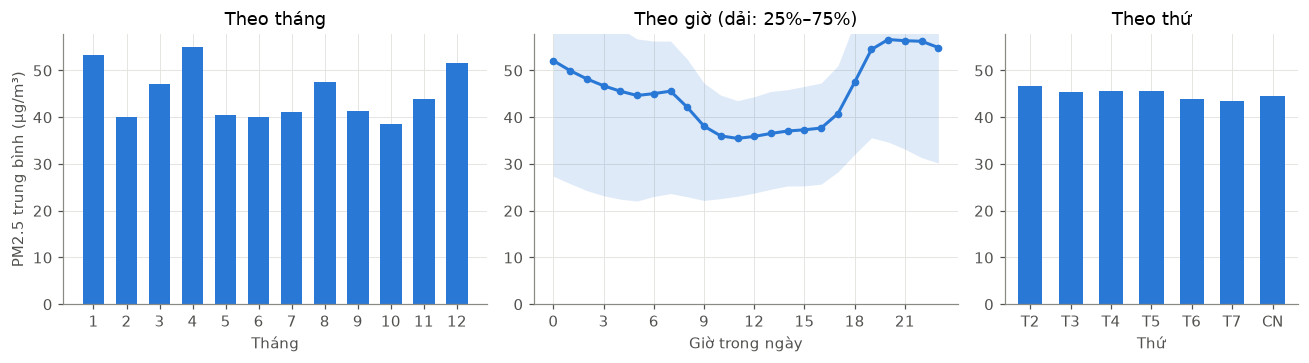

,giờ thấp nhất,giờ cao nhất,chênh lệch theo giờ (µg/m³),chênh lệch theo thứ (µg/m³)
0,11,20,21.1,3.2


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.3, 1.3, 0.9]})
month = df["pm2_5"].groupby(df.index.month)
axes[0].bar(range(1, 13), month.mean(), color=PALETTE[0], width=0.65)
axes[0].set(xticks=range(1, 13), xlabel="Tháng", ylabel="PM2.5 trung bình (µg/m³)", title="Theo tháng")

hour = df["pm2_5"].groupby(df.index.hour)
axes[1].plot(range(24), hour.mean(), color=PALETTE[0], linewidth=2, marker="o", markersize=4)
axes[1].fill_between(range(24), hour.quantile(0.25), hour.quantile(0.75), color=PALETTE[0], alpha=0.15, linewidth=0)
axes[1].set(xticks=range(0, 24, 3), xlabel="Giờ trong ngày", title="Theo giờ (dải: 25%–75%)")

dow = df["pm2_5"].groupby(df.index.dayofweek)
axes[2].bar(range(7), dow.mean(), color=PALETTE[0], width=0.6)
axes[2].set(xticks=range(7), xticklabels=["T2", "T3", "T4", "T5", "T6", "T7", "CN"], xlabel="Thứ", title="Theo thứ")
for ax in axes[1:]:
    ax.set_ylim(axes[0].get_ylim())
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_pm25_cycles.png"), bbox_inches="tight")
plt.show()
pd.DataFrame({"giờ thấp nhất": [hour.mean().idxmin()], "giờ cao nhất": [hour.mean().idxmax()],
              "chênh lệch theo giờ (µg/m³)": [hour.mean().max() - hour.mean().min()],
              "chênh lệch theo thứ (µg/m³)": [dow.mean().max() - dow.mean().min()]}).round(1)

**Nhận xét.**
- **Theo giờ:** PM2.5 thấp nhất vào khoảng 11 giờ trưa và cao nhất vào khoảng 20 giờ tối, chênh nhau khoảng 21 µg/m³. Ban ngày nắng làm không khí sát mặt đất xáo trộn mạnh nên bụi được pha loãng; tối và đêm lớp không khí ổn định hơn nên bụi tích tụ, cộng thêm giao thông giờ tan tầm. Vì vậy mô hình cần biết giờ trong ngày.
- **Theo tháng:** số của mô hình CAMS không cao hẳn vào mùa đông như số đo trạm thường thấy: tháng 1, 4 và 12 cao nhất (khoảng 52–55 µg/m³), tháng 10 thấp nhất (khoảng 39 µg/m³).
- **Theo thứ:** chênh lệch nhỏ (khoảng 3 µg/m³), nên thứ trong tuần chỉ đóng vai phụ.

Các chu kỳ này được đưa vào mô hình dưới dạng cặp sin, cos của giờ, thứ và ngày trong năm, để 23 giờ và 0 giờ được coi là gần nhau.

## 5. Phân phối của PM2.5: vì sao biến đổi log

PM2.5 lệch phải: phần lớn các giờ ở mức 20–60 µg/m³ nhưng có đuôi dài tới hơn 200 µg/m³. Biến đổi $\log(1 + x)$ kéo phân phối về gần đối xứng hơn, giúp mô hình học bằng MSE không bị vài giờ rất cao chi phối. Khi tính chỉ số, dự báo được đổi ngược về µg/m³.

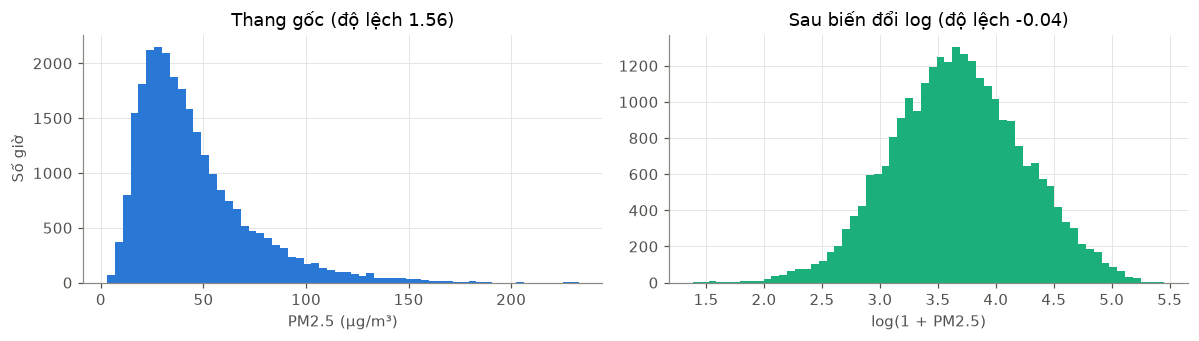

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(df["pm2_5"], bins=60, color=PALETTE[0])
axes[0].set(xlabel="PM2.5 (µg/m³)", ylabel="Số giờ", title=f"Thang gốc (độ lệch {df['pm2_5'].skew():.2f})")
axes[1].hist(np.log1p(df["pm2_5"]), bins=60, color=PALETTE[2])
axes[1].set(xlabel="log(1 + PM2.5)", title=f"Sau biến đổi log (độ lệch {np.log1p(df['pm2_5']).skew():.2f})")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_pm25_distribution.png"), bbox_inches="tight")
plt.show()

## 6. Tự tương quan: PM2.5 hiện tại nói được gì về tương lai

Hệ số tự tương quan ở độ trễ $k$ là tương quan giữa PM2.5 lúc $t$ và lúc $t - k$. Đây là căn cứ để chọn độ dài cửa sổ đầu vào.

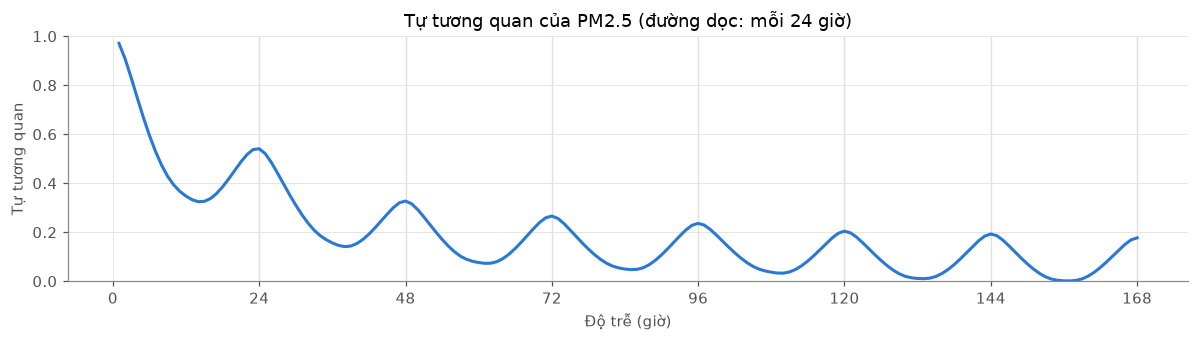

,1,2,3,6,12,24,48,72,168
tự tương quan,0.971,0.908,0.83,0.595,0.347,0.541,0.327,0.266,0.177


In [7]:
lags = np.arange(1, 169)
acf = np.array([df["pm2_5"].autocorr(int(k)) for k in lags])
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(lags, acf, color=PALETTE[0], linewidth=2)
for k in (24, 48, 72, 96, 120, 144, 168):
    ax.axvline(k, color="#c9c8c3", linewidth=0.8, zorder=0)
ax.set(xlabel="Độ trễ (giờ)", ylabel="Tự tương quan", title="Tự tương quan của PM2.5 (đường dọc: mỗi 24 giờ)",
       xticks=range(0, 169, 24), ylim=(0, 1))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_pm25_autocorrelation.png"), bbox_inches="tight")
plt.show()
pd.Series({k: df["pm2_5"].autocorr(k) for k in (1, 2, 3, 6, 12, 24, 48, 72, 168)}, name="tự tương quan").to_frame().T.round(3)

**Nhận xét.** Tự tương quan rất cao ở 1–2 giờ (0,97 và 0,91) nên "giữ nguyên giá trị hiện tại" đã là một dự báo khá tốt cho 2 giờ tới; mô hình học sâu phải thắng được mốc này. Tương quan giảm nhanh tới khoảng 12 giờ rồi **nhô lên ở 24 giờ** (chu kỳ ngày) và yếu dần sau 48–72 giờ. Vì vậy cửa sổ đầu vào 48 giờ chứa cả diễn biến gần nhất lẫn hai chu kỳ ngày; notebook 02 thử thêm 24 và 72 giờ.

## 7. Quan hệ giữa PM2.5 và các biến khác

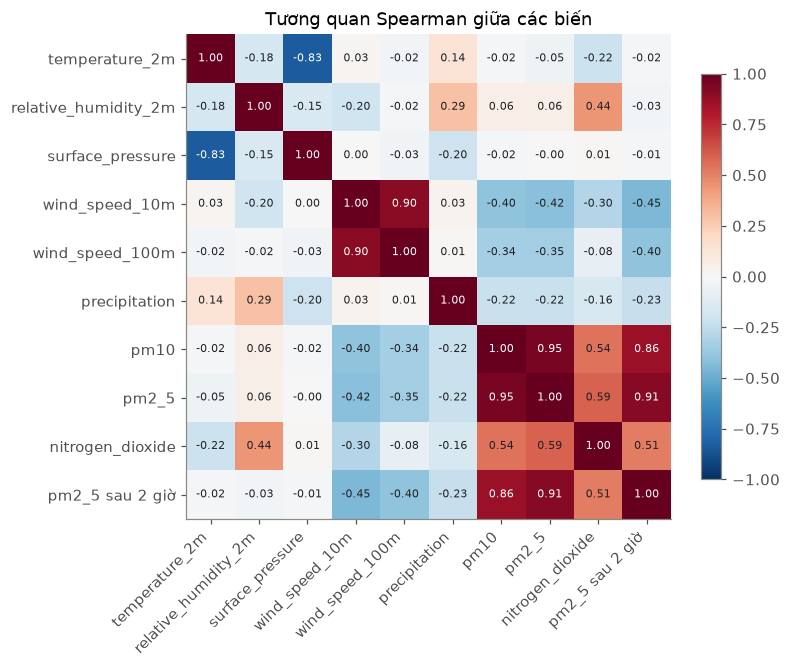

,pm2_5 sau 2 giờ
pm2_5,0.911
pm10,0.861
nitrogen_dioxide,0.508
wind_speed_10m,-0.446
wind_speed_100m,-0.401
precipitation,-0.227
relative_humidity_2m,-0.026
temperature_2m,-0.020
surface_pressure,-0.011


In [8]:
future = df["pm2_5"].shift(-2).rename("pm2_5 sau 2 giờ")      # đích của Task 1
corr_df = pd.concat([df[VARIABLES], future], axis=1).dropna()
corr = corr_df.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#202124")
ax.grid(False)
ax.set_title("Tương quan Spearman giữa các biến")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_correlation.png"), bbox_inches="tight")
plt.show()
corr["pm2_5 sau 2 giờ"].drop("pm2_5 sau 2 giờ").sort_values(key=np.abs, ascending=False).round(3).to_frame()

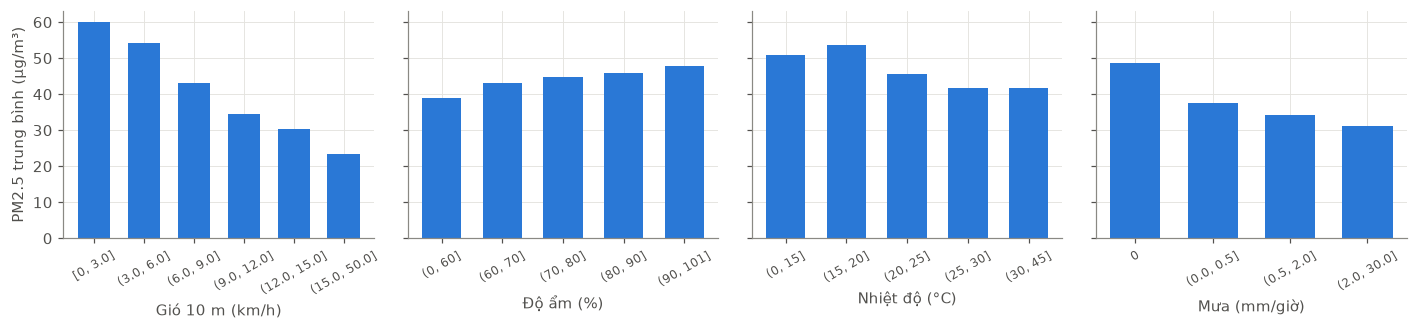

In [9]:
# PM2.5 trung bình theo từng khoảng giá trị của các biến khí tượng
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, (col, bins, label) in zip(axes, [
        ("wind_speed_10m", [-0.01, 3, 6, 9, 12, 15, 50], "Gió 10 m (km/h)"),
        ("relative_humidity_2m", [0, 60, 70, 80, 90, 101], "Độ ẩm (%)"),
        ("temperature_2m", [0, 15, 20, 25, 30, 45], "Nhiệt độ (°C)"),
        ("precipitation", [-0.01, 0, 0.5, 2, 30], "Mưa (mm/giờ)")]):
    groups = pd.cut(df[col], bins)
    mean = df.groupby(groups, observed=True)["pm2_5"].mean()
    ax.bar(range(len(mean)), mean.values, color=PALETTE[0], width=0.65)
    ax.set_xticks(range(len(mean)), [str(i).replace("(-0.01, 0.0]", "0").replace("(-0.01, ", "[0, ") for i in mean.index], rotation=30, fontsize=8)
    ax.set_xlabel(label)
axes[0].set_ylabel("PM2.5 trung bình (µg/m³)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "eda_pm25_vs_weather.png"), bbox_inches="tight")
plt.show()

**Nhận xét.**
- PM2.5 tương quan rất chặt với PM10 (hai loại bụi cùng nguồn, cùng do mô hình CAMS tính) và khá chặt với NO2 (khí thải giao thông).
- Gió mạnh làm PM2.5 giảm rõ: bụi bị thổi đi (từ khoảng 60 µg/m³ khi gần như lặng gió xuống khoảng 23 µg/m³ khi gió trên 15 km/h). Mưa cũng làm PM2.5 thấp hơn vì bụi bị rửa trôi.
- Độ ẩm cao và trời lạnh đi kèm PM2.5 cao hơn một chút, nhưng tương quan tổng thể của hai biến này với PM2.5 sau 2 giờ gần bằng 0.
- Các biến khí tượng có quan hệ với PM2.5 nhưng yếu hơn nhiều so với chính PM2.5 quá khứ. Notebook 02 kiểm tra xem bỏ các biến khí tượng thì mô hình kém đi bao nhiêu (thí nghiệm E3).

## 8. Mốc so sánh: dự báo "giữ nguyên" (persistence)

Cách dự báo đơn giản nhất là lấy PM2.5 hiện tại làm dự báo cho các giờ tới. Bảng dưới tính bốn chỉ số R², NSE, MAE, RMSE (theo slide chương 2.1, hàm trong `metrics.py`) của cách này, cho từng tập và từng tầm dự báo 1–5 giờ, dùng đúng cách cắt cửa sổ của Task 1–2. Mô hình học sâu chỉ có ý nghĩa khi thắng rõ mốc này.

In [10]:
rows = []
w = make_windows(df, VARIABLES, "pm2_5", lookback=48, horizons=(1, 2, 3, 4, 5))
current = w["X"][:, -1, VARIABLES.index("pm2_5")]                 # PM2.5 tại giờ hiện tại t
for split in ["train", "validation", "test"]:
    m = w["split"] == split
    for k, h in enumerate((1, 2, 3, 4, 5)):
        rows.append({"tập": split, "dự báo sau (giờ)": h, **metrics.regression_report(w["y"][m, k], current[m])})
persistence = pd.DataFrame(rows).set_index(["tập", "dự báo sau (giờ)"])
persistence.to_csv(os.path.join(RESULT_DIR, "persistence_baseline.csv"))
persistence.round(3).unstack(0)

R2                      NSE                       MAE  \
tập                test  train validation   test  train validation    test   
dự báo sau (giờ)                                                             
1                 0.926  0.946      0.941  0.925  0.945      0.940   5.464   
2                 0.779  0.834      0.823  0.765  0.827      0.814  10.026   
3                 0.615  0.705      0.688  0.568  0.680      0.658  14.073   
4                 0.461  0.582      0.560  0.357  0.526      0.496  17.626   
5                 0.329  0.473      0.450  0.148  0.376      0.340  20.740   

                                       RMSE                     
tập                train validation    test   train validation  
dự báo sau (giờ)                                                
1                  3.616      4.859   8.805   5.652      7.825  
2                  6.615      8.857  15.560  10.014     13.769  
3                  9.145     12.168  21.116  13.610     18.648  
4                 11.314     14.961  25.756  16.571     22.636  
5                 13.155     17.334  29.657  19.004     25.894

**Nhận xét.** Trên tập test, dự báo giữ nguyên cho 2 giờ tới (Task 1) đạt R² = 0,779, NSE = 0,765, MAE = 10,0 µg/m³, RMSE = 15,6 µg/m³. Sai số tăng nhanh theo tầm dự báo: ở 5 giờ tới NSE chỉ còn khoảng 0,15. Tập test có sai số lớn hơn train vì có mùa đông với những đợt ô nhiễm cao và thay đổi nhanh.

## 9. Tóm tắt cho phần mô tả dữ liệu của báo cáo

| Mục | Nội dung |
|---|---|
| Nguồn | Open-Meteo: Historical Weather API (ERA5) và Air Quality API (CAMS), Hà Nội |
| Thời gian | 01/01/2023 – 31/12/2025, theo giờ, 26.304 giờ, không thiếu giờ nào |
| Biến | PM2.5 (đích), PM10, NO2, nhiệt độ, độ ẩm, áp suất, gió 10 m và 100 m, lượng mưa |
| Chia tập | train 2023–2024 (17.544 giờ), validation 01–06/2025 (4.344 giờ), test 07–12/2025 (4.416 giờ) |
| Đặc điểm chính | lệch phải (dùng log); tự tương quan rất cao ở 1–2 giờ và có chu kỳ 24 giờ; gió mạnh và mưa làm PM2.5 giảm |
| Mốc cần thắng (Task 1, test) | giữ nguyên: R² 0,779, NSE 0,765, MAE 10,0, RMSE 15,6 µg/m³ |